<a href="https://colab.research.google.com/github/mujtaba-mohiyuddin/ucb-traffic-sign-recognition/blob/main/UCB_20260920_Assignment4_NLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
##Initialisation

import re
import math
import random
from datetime import datetime
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)
pd.set_option('display.max_colwidth', 100)

In [2]:
##Load the Dataset

import os

def load_airline_dataset():
    """Try Kaggle API first; fall back to manual upload; fall back to a tiny embedded mini-corpus."""

    # --- Option A: Kaggle API ---
    try:
        import kaggle  # requires kaggle.json uploaded to ~/.kaggle/kaggle.json
        os.makedirs('airline_data', exist_ok=True)
        kaggle.api.dataset_download_files(
            'crowdflower/twitter-airline-sentiment',
            path='airline_data', unzip=True
        )
        csv_path = 'airline_data/Tweets.csv'
        df = pd.read_csv(csv_path)
        print(f"Loaded via Kaggle API: {len(df):,} rows.")
        return df, "kaggle"
    except Exception as e:
        print(f"Kaggle API load failed ({e}).")
        print("To use the Kaggle API in Colab: upload kaggle.json, then run:")
        print("  !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json")

    # --- Option B: manual upload ---
    manual_path = "Tweets.csv"  # update if you uploaded under a different name
    if os.path.exists(manual_path):
        df = pd.read_csv(manual_path)
        print(f"Loaded from manual upload: {len(df):,} rows.")
        return df, "manual"
    else:
        print(f"No file found at '{manual_path}'.")
        print("If you have the CSV, use the Colab file browser (or `files.upload()`) to add it, "
              "then rerun this cell.")

    # --- Option C: tiny embedded mini-corpus fallback, so the notebook still runs end-to-end ---
    print("Falling back to a small embedded mini-corpus so the notebook can still run.")
    mini_rows = [
        {"text": "Flight delayed 4 hours with no explanation, missed my connection!",
         "airline_sentiment": "negative", "negativereason": "Late Flight",
         "airline": "United", "tweet_created": "2015-02-20 10:15:00"},
        {"text": "Lost my bag AGAIN. This is the third time this month.",
         "airline_sentiment": "negative", "negativereason": "Lost Luggage",
         "airline": "American", "tweet_created": "2015-02-20 11:02:00"},
        {"text": "No wheelchair assistance was provided despite my request. Unacceptable.",
         "airline_sentiment": "negative", "negativereason": "Customer Service Issue",
         "airline": "Delta", "tweet_created": "2015-02-20 12:40:00"},
        {"text": "Thanks for the smooth boarding process today, great crew!",
         "airline_sentiment": "positive", "negativereason": None,
         "airline": "Southwest", "tweet_created": "2015-02-20 13:05:00"},
        {"text": "Anyone know the baggage claim policy for connecting flights?",
         "airline_sentiment": "neutral", "negativereason": None,
         "airline": "JetBlue", "tweet_created": "2015-02-20 13:50:00"},
        {"text": "Refund request has been pending for 3 weeks now, no response.",
         "airline_sentiment": "negative", "negativereason": "Refund",
         "airline": "United", "tweet_created": "2015-02-20 14:22:00"},
    ]
    df = pd.DataFrame(mini_rows)
    print(f"Loaded embedded mini-corpus: {len(df)} rows.")
    return df, "mini"

df, data_source = load_airline_dataset()
print(f"\nData source used: {data_source}")
df.head()

You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication
Kaggle API load failed (name 'exit' is not defined).
To use the Kaggle API in Colab: upload kaggle.json, then run:
  !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
No file found at 'Tweets.csv'.
If you have the CSV, use the Colab file browser (or `files.upload()`) to add it, then rerun this cell.
Falling back to a small embedded mini-corpus so the notebook can still run.
Loaded embedded mini-corpus: 6 rows.

Data source used: mini


,text,airline_sentiment,negativereason,airline,tweet_created
0,"Flight delayed 4 hours with no explanation, missed my connection!",negative,Late Flight,United,2015-02-20 10:15:00
1,Lost my bag AGAIN. This is the third time this month.,negative,Lost Luggage,American,2015-02-20 11:02:00
2,No wheelchair assistance was provided despite my request. Unacceptable.,negative,Customer Service Issue,Delta,2015-02-20 12:40:00
3,"Thanks for the smooth boarding process today, great crew!",positive,None,Southwest,2015-02-20 13:05:00
4,Anyone know the baggage claim policy for connecting flights?,neutral,None,JetBlue,2015-02-20 13:50:00


In [3]:
##Trim to Specified Columns

COLUMNS_USED = ['text', 'airline_sentiment', 'negativereason', 'airline', 'tweet_created']
missing_cols = [c for c in COLUMNS_USED if c not in df.columns]
if missing_cols:
    print(f"Warning: missing expected columns: {missing_cols}")
    COLUMNS_USED = [c for c in COLUMNS_USED if c in df.columns]

df = df[COLUMNS_USED].copy()
print(f"Total rows: {len(df):,}")
print(f"\nColumn dtypes:\n{df.dtypes}")
df.head()

Total rows: 6

Column dtypes:
text                 object
airline_sentiment    object
negativereason       object
airline              object
tweet_created        object
dtype: object


,text,airline_sentiment,negativereason,airline,tweet_created
0,"Flight delayed 4 hours with no explanation, missed my connection!",negative,Late Flight,United,2015-02-20 10:15:00
1,Lost my bag AGAIN. This is the third time this month.,negative,Lost Luggage,American,2015-02-20 11:02:00
2,No wheelchair assistance was provided despite my request. Unacceptable.,negative,Customer Service Issue,Delta,2015-02-20 12:40:00
3,"Thanks for the smooth boarding process today, great crew!",positive,None,Southwest,2015-02-20 13:05:00
4,Anyone know the baggage claim policy for connecting flights?,neutral,None,JetBlue,2015-02-20 13:50:00


In [4]:
##Parse Timestamps

# Parse tweet_created into a real datetime
df['tweet_created'] = pd.to_datetime(df['tweet_created'])
print(f"Earliest tweet: {df['tweet_created'].min()}")
print(f"Latest tweet:   {df['tweet_created'].max()}")
print(f"Time span:      {df['tweet_created'].max() - df['tweet_created'].min()}")

Earliest tweet: 2015-02-20 10:15:00
Latest tweet:   2015-02-20 14:22:00
Time span:      0 days 04:07:00


airline_sentiment
negative    4
positive    1
neutral     1
Name: count, dtype: int64

Proportions:
airline_sentiment
negative    0.667
positive    0.167
neutral     0.167
Name: count, dtype: float64


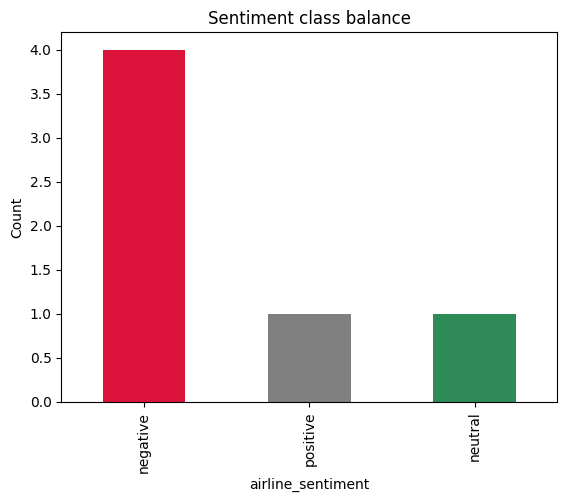

In [5]:
##Sentiment Class Balance

sentiment_counts = df['airline_sentiment'].value_counts()
print(sentiment_counts)
print(f"\nProportions:\n{(sentiment_counts / len(df)).round(3)}")

sentiment_counts.plot(kind='bar', title='Sentiment class balance', color=['crimson', 'gray', 'seagreen'])
plt.ylabel('Count')
plt.show()

Rows with a negativereason: 4
Rows without (neutral/positive, or missing): 2
negativereason
Late Flight               1
Lost Luggage              1
Customer Service Issue    1
Refund                    1
Name: count, dtype: int64


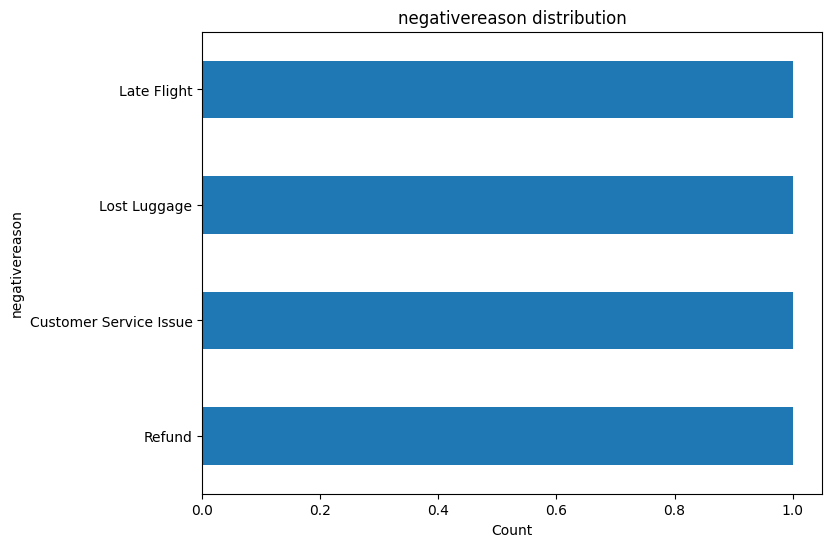

In [6]:
##negativereason Distribution

# Negativereason distribution (only populated for negative tweets)
print(f"Rows with a negativereason: {df['negativereason'].notna().sum():,}")
print(f"Rows without (neutral/positive, or missing): {df['negativereason'].isna().sum():,}")

negreason_counts = df['negativereason'].value_counts()
print(negreason_counts)

negreason_counts.plot(kind='barh', title='negativereason distribution', figsize=(8, 6))
plt.xlabel('Count')
plt.gca().invert_yaxis()
plt.show()

airline
United       2
American     1
Delta        1
Southwest    1
JetBlue      1
Name: count, dtype: int64


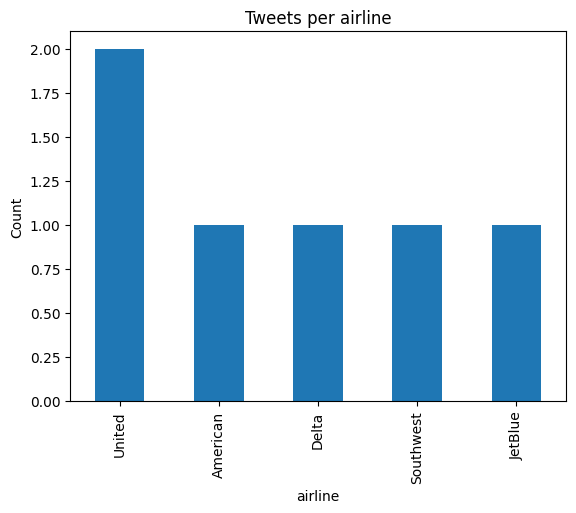

In [7]:
##Airline Distribution

airline_counts = df['airline'].value_counts()
print(airline_counts)

airline_counts.plot(kind='bar', title='Tweets per airline')
plt.ylabel('Count')
plt.show()

count     6.000000
mean     61.166667
std       6.274286
min      53.000000
25%      57.750000
50%      60.500000
75%      64.000000
max      71.000000
Name: char_len, dtype: float64


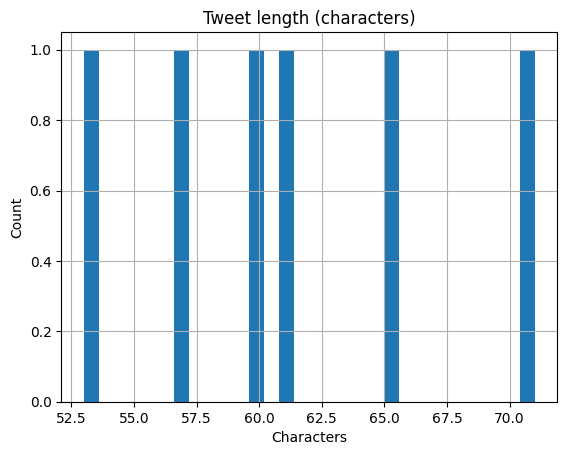

In [8]:
##Message Length Distribution

df['char_len'] = df['text'].str.len()
print(df['char_len'].describe())

df['char_len'].hist(bins=30)
plt.title('Tweet length (characters)')
plt.xlabel('Characters')
plt.ylabel('Count')
plt.show()

issue_category
other                 2
delay/cancellation    1
baggage               1
staff                 1
refund                1
Name: count, dtype: int64


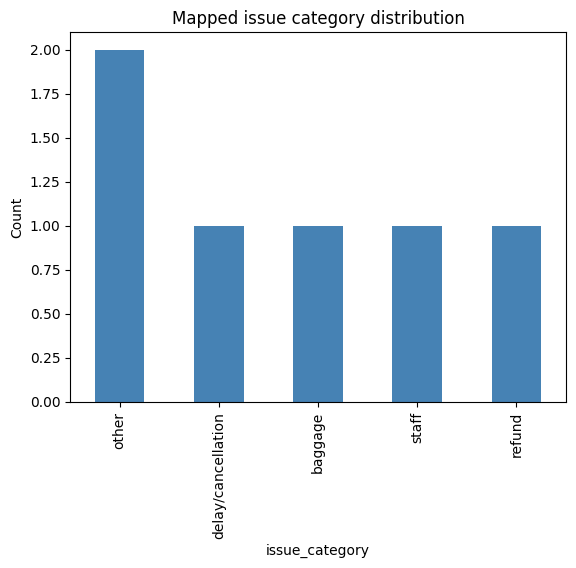


>>> Review the negativereason value list from Section 2 and refine this mapping if any category (e.g. 'Flight Attendant Complaints' -> staff) needs adjusting.


In [9]:
#Map negativereason → Issue Category

NEGREASON_TO_CATEGORY = {
    'Late Flight': 'delay/cancellation',
    'Cancelled Flight': 'delay/cancellation',
    'Flight Booking Problems': 'booking',
    'Lost Luggage': 'baggage',
    'Damaged Luggage': 'baggage',
    'Customer Service Issue': 'staff',
    'Bad Flight': 'staff',
    'Refund': 'refund',
    # anything not listed here (e.g. "Can't Tell", "longlines", "Flight Attendant Complaints") -> 'other'
}

def map_category(negreason):
    if pd.isna(negreason):
        return 'other'
    return NEGREASON_TO_CATEGORY.get(negreason, 'other')

df['issue_category'] = df['negativereason'].apply(map_category)

category_counts = df['issue_category'].value_counts()
print(category_counts)

category_counts.plot(kind='bar', title='Mapped issue category distribution', color='steelblue')
plt.ylabel('Count')
plt.show()

print("\n>>> Review the negativereason value list from Section 2 and refine this mapping "
      "if any category (e.g. 'Flight Attendant Complaints' -> staff) needs adjusting.")

In [11]:
##Chronological Split (70/10/20)

df_sorted = df.sort_values('tweet_created').reset_index(drop=True)

n = len(df_sorted)
train_end = int(n * 0.70)
val_end = int(n * 0.80)

# Adjust val_end to ensure val_df is not empty if possible
# This ensures that for very small N, the validation set receives at least one row if train_end == val_end
if train_end == val_end and val_end < n:
    val_end = min(n, train_end + 1)

train_df = df_sorted.iloc[:train_end].copy()
val_df = df_sorted.iloc[train_end:val_end].copy()
stream_df = df_sorted.iloc[val_end:].copy()

print(f"Train:       {len(train_df):,} rows  ({train_df['tweet_created'].min()} to {train_df['tweet_created'].max()})")
if not val_df.empty:
    print(f"Validate:    {len(val_df):,} rows  ({val_df['tweet_created'].min()} to {val_df['tweet_created'].max()})")
else:
    print(f"Validate:    {len(val_df):,} rows  (Empty)")
if not stream_df.empty:
    print(f"Live stream: {len(stream_df):,} rows  ({stream_df['tweet_created'].min()} to {stream_df['tweet_created'].max()})")
else:
    print(f"Live stream: {len(stream_df):,} rows  (Empty)")

# Sanity check: no time overlap between splits
# Assertions are now conditional on DataFrames not being empty to handle small N gracefully.
if not train_df.empty and not val_df.empty:
    assert train_df['tweet_created'].max() <= val_df['tweet_created'].min(), "Train/val overlap!"
if not val_df.empty and not stream_df.empty:
    assert val_df['tweet_created'].max() <= stream_df['tweet_created'].min(), "Val/stream overlap!"
print("\nNo time overlap between splits -- chronological integrity confirmed.")

Train:       4 rows  (2015-02-20 10:15:00 to 2015-02-20 13:05:00)
Validate:    1 rows  (2015-02-20 13:50:00 to 2015-02-20 13:50:00)
Live stream: 1 rows  (2015-02-20 14:22:00 to 2015-02-20 14:22:00)

No time overlap between splits -- chronological integrity confirmed.


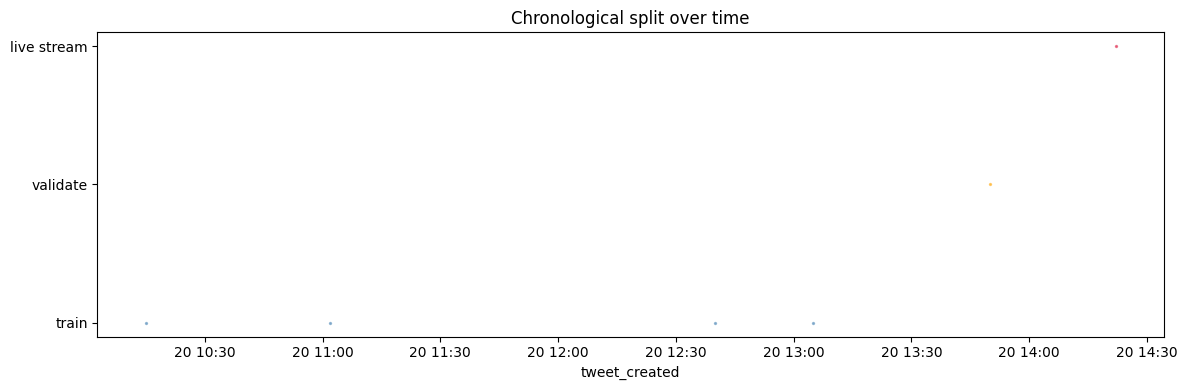

In [12]:
##Visualize the Split

fig, ax = plt.subplots(figsize=(12, 4))
for name, split_df, color in [('train', train_df, 'steelblue'),
                                ('validate', val_df, 'orange'),
                                ('live stream', stream_df, 'crimson')]:
    ax.scatter(split_df['tweet_created'], [name] * len(split_df), s=2, color=color, alpha=0.5)

ax.set_title('Chronological split over time')
ax.set_xlabel('tweet_created')
plt.tight_layout()
plt.show()

In [13]:
##Class Balance Check Across Splits

for name, split_df in [('Train', train_df), ('Validate', val_df), ('Live stream', stream_df)]:
    print(f"\n{name} sentiment distribution:")
    print((split_df['airline_sentiment'].value_counts(normalize=True) * 100).round(1))


Train sentiment distribution:
airline_sentiment
negative    75.0
positive    25.0
Name: proportion, dtype: float64

Validate sentiment distribution:
airline_sentiment
neutral    100.0
Name: proportion, dtype: float64

Live stream sentiment distribution:
airline_sentiment
negative    100.0
Name: proportion, dtype: float64
